<a href="https://colab.research.google.com/github/JonaEmmOfCruz/Machine-learning/blob/main/Hands-on%204/Hands_on_4_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><strong>Classification in Machine Learning: Linear Classifiers, The Perceptron</strong></h1>


El Perceptrón es la unidad básica de una Red Neuronal Artificial. Es un clasificador lineal que toma variables de entrada ($X$), les asigna una importancia o "peso" ($w$), suma los resultados junto a un ajuste llamado sesgo ($b$), y decide si la respuesta pertenece a la Clase 1 o a la Clase 0 mediante una función de activación.

<h2><strong>Modelo matemático y analítico</strong></h2>

<h4><strong>Suma Ponderada $z$</strong></h4>

$$z = w_1x_1 + w_2x_2 + \cdot \cdot \cdot + w_nx_n + b$$

<br>

<h4><strong>Función de activación</strong></h4>

<br>

$$\hat{y} = \begin{cases} 1 & \text{si } z \geq 0 \\ 0 & \text{si } z < 0 \end{cases}$$

<br>

<h4><strong>Regla de Actualización de Pesos</strong></h4>

<br>

$$w_i^{(t+1)} = w_i^{(t)} + \eta \cdot (y - \hat{y}) \cdot x_i$$

$$b^{(t+1)} = b^{(t)} + \eta \cdot (y - \hat{y})$$


<h2><strong>Métricas de evaluación para clasificación</strong></h2>

| Métrica | Formúla &nbsp; &nbsp; | Descripción |
| :------ | :---------------: | :------ |
| **Exactitud** | $\frac{TP + TN}{TP + TN + FP +FN}$ | Mide la proporción de las predicciones correctas sobre el total de las muestras |
| **Matriz de <br> confusión** | $
\begin{pmatrix}
TN & FP \\
FN & TP
\end{pmatrix}
$ | Cuadro cruzado entre los valores reales y las predicciones |
| **Precisión** | $\frac{TP}{TP + FP}$ | Cuadro cruzado entre los valores reales y las predicciones |
| **Sensibilidad** | $\frac{TP}{TP + FN}$ | Mide la armónica entre precisión y sensibilidad |
| **Puntaje F1 <br> Score** | $\frac{Precision * Recall}{Precision + Recall}$ | Media armónica entre la precisión y la sensibilidad|

<h2><strong>Implementación en Python</strong></h2>

<h3><strong>Importación de librerías</strong></h3>

In [1]:
# Se importa para la computación numérica eficiente y operadciones matriciales
import numpy as np

# Se importa para estructurar la informacion y leer los datos tabulares
import pandas as pd

# Se importa para crear graficos
import matplotlib.pyplot as plt

# Se importa seaborn para aplicar estilos
import seaborn as sns

# Se importa para dividir los datos en entrenamiento y pruebas
from sklearn.model_selection import train_test_split

# Se importa para estandarizar la media y la varianza
from sklearn.preprocessing import StandardScaler

# Se importa para construir y entresar al modelo
from sklearn.linear_model import Perceptron

# Se importa las metricas para evaluar la calidad y la precisión
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")

<h3><strong>Importación y recolección del dataset desde Drive</strong></h3>



In [12]:
# Monto el Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Defino la ruta del archivo
ruta = '/content/drive/MyDrive/Colab Notebooks/dataset/Advertising.csv'

# Leo el archivo CSV
df = pd.read_csv(ruta)

# Muestro las primeras filas
df.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


<h3><strong>Formateo de información</strong></h3>



In [14]:
# 1. Identificar variables X e Y
columna_y = 'Sales'
columnas_x = [col for col in df.columns if col not in [columna_y, 'Unnamed: 0']]

X = df[columnas_x].values
Y = df[columna_y].values

# 2. Definir umbral binarizador
umbral = df[columna_y].mean()
Y_binario = np.where(Y > umbral, 1, 0)

print(f"Variables independientes (X): {columnas_x}")
print(f"Variable dependiente (y): {columna_y}")
print(f"Umbral de corte (Media): {umbral:.2f}")

Variables independientes (X): ['TV', 'Radio', 'Newspaper']
Variable dependiente (y): Sales
Umbral de corte (Media): 14.02


<h3><strong>Gráfico del DataSet</strong></h3>



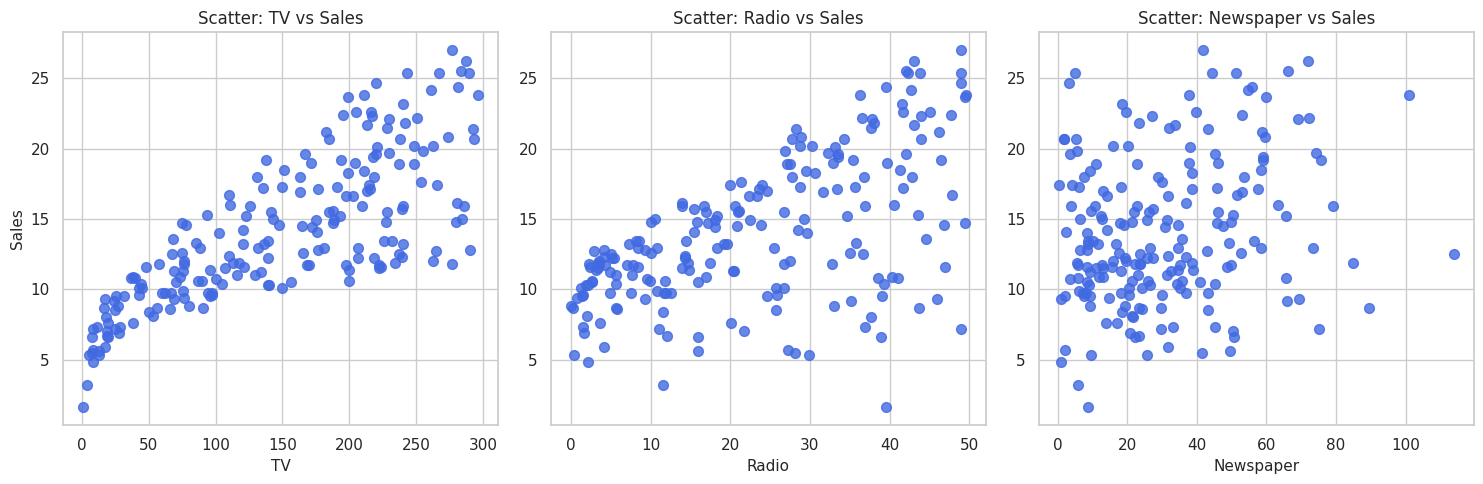

In [15]:
# Crear una figura con ancho dinámico dependiendo de la cantidad de variables
fig, axs = plt.subplots(1, len(columnas_x), figsize=(5 * len(columnas_x), 5))

# Si solo hay una columna, matplotlib devuelve un objeto único.
# Lo convertimos en una lista para evitar el error "not subscriptable".
if len(columnas_x) == 1:
    axs = [axs]

# Iterar sobre cada variable independiente para dibujarla contra Y
for i, col_x in enumerate(columnas_x):
    # Dibujar el gráfico de dispersión en su respectivo subgráfico
    axs[i].scatter(df[col_x], df[columna_y], color='royalblue', edgecolor='royalblue', s=50, alpha=0.8)

    # Asignar títulos y etiquetas a cada uno
    axs[i].set_title(f'Scatter: {col_x} vs {columna_y}', fontsize=12)
    axs[i].set_xlabel(col_x, fontsize=11)

    # Solo poner la etiqueta Y en el primer gráfico para no saturar
    if i == 0:
        axs[i].set_ylabel(columna_y, fontsize=11)

# Ajustar el espacio para que no se empalmen y mostrar
plt.tight_layout()
plt.show()

<h3><strong>Selección y división de los datos de entrenamiento y prueba</strong></h3>



In [16]:
# División de los datos
X_train, X_test, y_train, y_test = train_test_split(
    X, Y_binario, test_size=0.3, random_state=42
)

# Mantenemos las Y continuas originales únicamente para graficar el umbral
_, _, Y_train_cont, Y_test_cont = train_test_split(
    X, Y, test_size=0.3, random_state=42
)

print(f"Muestras para Entrenamiento: {X_train.shape[0]}")
print(f"Muestras para Prueba: {X_test.shape[0]}")

Muestras para Entrenamiento: 140
Muestras para Prueba: 60


Grafico de datos de prueba y entrenamiento

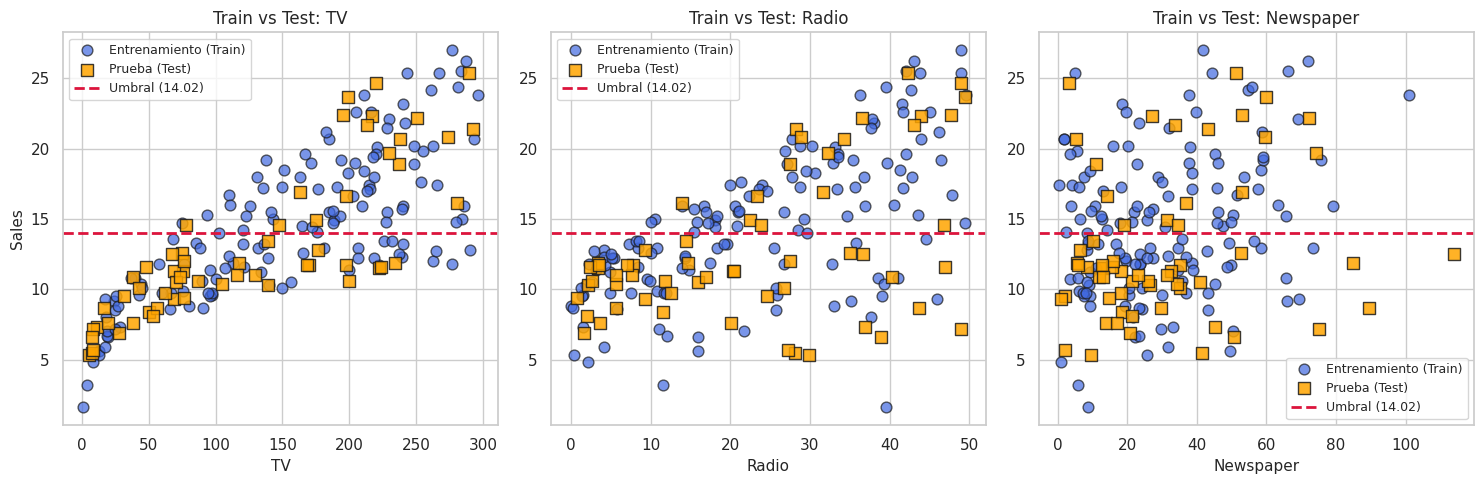

In [17]:
fig, axs = plt.subplots(1, len(columnas_x), figsize=(5 * len(columnas_x), 5))
if len(columnas_x) == 1:
    axs = [axs]

for i, col_x in enumerate(columnas_x):
    # Puntos de Entrenamiento (Círculos Azules)
    axs[i].scatter(X_train[:, i], Y_train_cont, color='royalblue', marker='o',
                   edgecolor='k', s=60, alpha=0.7, label='Entrenamiento (Train)')

    # Puntos de Prueba (Cuadrados Naranjas)
    axs[i].scatter(X_test[:, i], Y_test_cont, color='orange', marker='s',
                   edgecolor='k', s=70, alpha=0.85, label='Prueba (Test)')

    # Umbral horizontal
    axs[i].axhline(y=umbral, color='crimson', linestyle='--', linewidth=2, label=f'Umbral ({umbral:.2f})')

    axs[i].set_title(f'Train vs Test: {col_x}', fontsize=12)
    axs[i].set_xlabel(col_x, fontsize=11)
    if i == 0:
        axs[i].set_ylabel(columna_y, fontsize=11)
    axs[i].legend(fontsize=9)

plt.tight_layout()
plt.show()

<h3><strong>Grafico de clases</strong></h3>



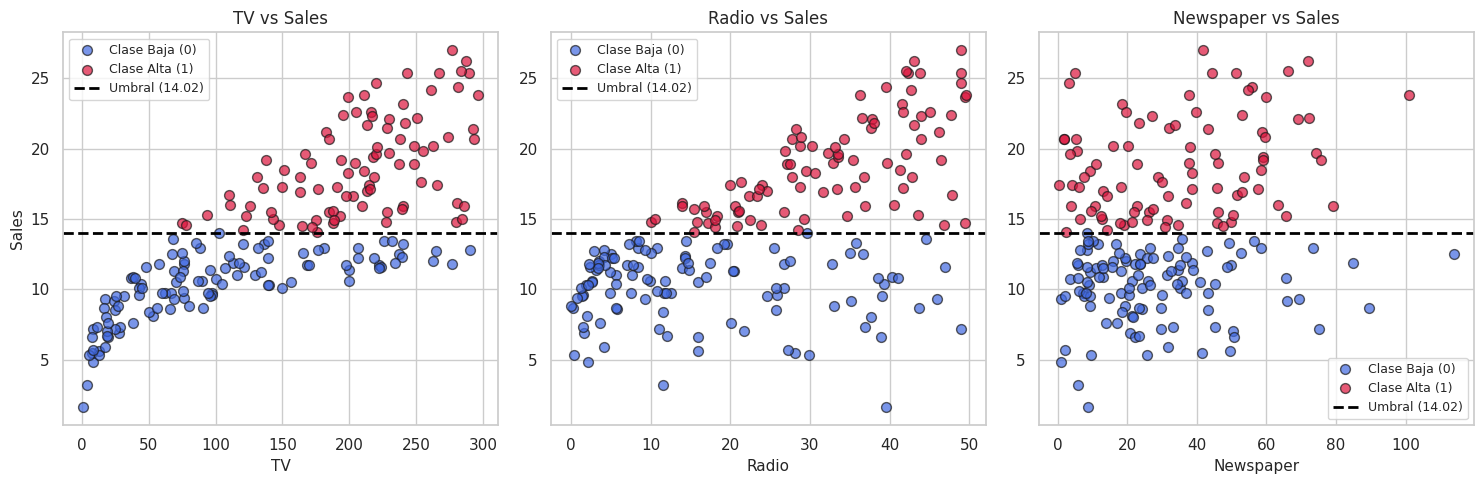

In [18]:
# Crear subgráficos según la cantidad de columnas en X
fig, axs = plt.subplots(1, len(columnas_x), figsize=(5 * len(columnas_x), 5))

# Asegurar que axs sea una lista iterable si solo hay 1 columna
if len(columnas_x) == 1:
    axs = [axs]

# Graficar cada columna contra Y separando por Clase Alta / Baja
for i, col_x in enumerate(columnas_x):

    # Puntos para Clase Baja (0) -> Azul
    axs[i].scatter(df[df[columna_y] <= umbral][col_x],
                   df[df[columna_y] <= umbral][columna_y],
                   color='royalblue', label='Clase Baja (0)', alpha=0.7, edgecolor='k', s=50)

    # Puntos para Clase Alta (1) -> Rojo
    axs[i].scatter(df[df[columna_y] > umbral][col_x],
                   df[df[columna_y] > umbral][columna_y],
                   color='crimson', label='Clase Alta (1)', alpha=0.7, edgecolor='k', s=50)

    # Línea horizontal del Umbral (Promedio)
    axs[i].axhline(y=umbral, color='black', linestyle='--', linewidth=2, label=f'Umbral ({umbral:.2f})')

    # Títulos y etiquetas
    axs[i].set_title(f'{col_x} vs {columna_y}', fontsize=12)
    axs[i].set_xlabel(col_x, fontsize=11)
    if i == 0:
        axs[i].set_ylabel(columna_y, fontsize=11)

    axs[i].legend(fontsize=9)

plt.tight_layout()
plt.show()

<h3><strong>Preprocesamiento y estandarización de los datos</strong></h3>



In [19]:
scaler = StandardScaler()

# Ajustar y transformar entrenamiento; transformar prueba
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Media aprendida: {scaler.mean_}")
print(f"Varianza aprendida: {scaler.var_}")

Media aprendida: [156.38928571  23.525       30.44785714]
Varianza aprendida: [6988.90267092  212.67016071  425.37349541]


<h3><strong>Entrenamiento del algoritmo perceptrón</strong></h3>


In [20]:
modelo_per = Perceptron(
    max_iter=1000,
    eta0=0.1,
    random_state=42,
    n_jobs=-1
)

modelo_per.fit(X_train_scaled, y_train)

w = modelo_per.coef_[0]
b = modelo_per.intercept_[0]

print("--- Modelo Entrenado ---")
for idx, col in enumerate(columnas_x):
    print(f"Peso sináptico (w_{idx+1}) para {col}: {w[idx]:.4f}")
print(f"Sesgo (b): {b:.4f}")
print(f"Épocas necesarias para converger: {modelo_per.n_iter_}")

--- Modelo Entrenado ---
Peso sináptico (w_1) para TV: 0.4591
Peso sináptico (w_2) para Radio: 0.8016
Peso sináptico (w_3) para Newspaper: 0.0776
Sesgo (b): -0.0000
Épocas necesarias para converger: 11


<h3><strong>Evaluación del conjuto de entrenamiento y prueba</strong></h3>


In [21]:
# Predicciones
y_train_pred = modelo_per.predict(X_train_scaled)
y_test_pred = modelo_per.predict(X_test_scaled)

# Métricas
acc_train = accuracy_score(y_train, y_train_pred)
acc_test = accuracy_score(y_test, y_test_pred)

matriz_train = confusion_matrix(y_train, y_train_pred)
matriz_test = confusion_matrix(y_test, y_test_pred)

# Resumen en Tabla
df_resumen = pd.DataFrame({
    'Métrica de evaluación': [
        'Exactitud (Accuracy)',
        'Verdaderos Negativos (TN)',
        'Falsos Positivos (FP)',
        'Falsos Negativos (FN)',
        'Verdaderos Positivos (TP)'
    ],
    'Entrenamiento (Train)': [
        f"{acc_train * 100:.2f}%",
        matriz_train[0, 0],
        matriz_train[0, 1],
        matriz_train[1, 0],
        matriz_train[1, 1]
    ],
    'Prueba (Test)': [
        f"{acc_test * 100:.2f}%",
        matriz_test[0, 0],
        matriz_test[0, 1],
        matriz_test[1, 0],
        matriz_test[1, 1]
    ]
})

display(df_resumen)

,Métrica de evaluación,Entrenamiento (Train),Prueba (Test)
0,Exactitud (Accuracy),87.86%,86.67%
1,Verdaderos Negativos (TN),61,35
2,Falsos Positivos (FP),8,7
3,Falsos Negativos (FN),9,1
4,Verdaderos Positivos (TP),62,17


<h3><strong>Graficos de la frontera de decisión ajustada</strong></h3>


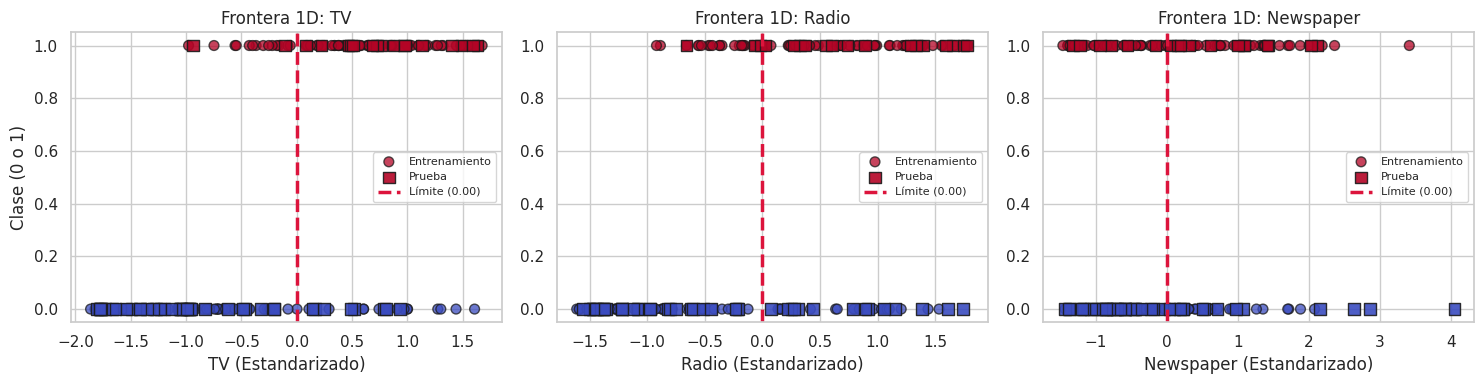

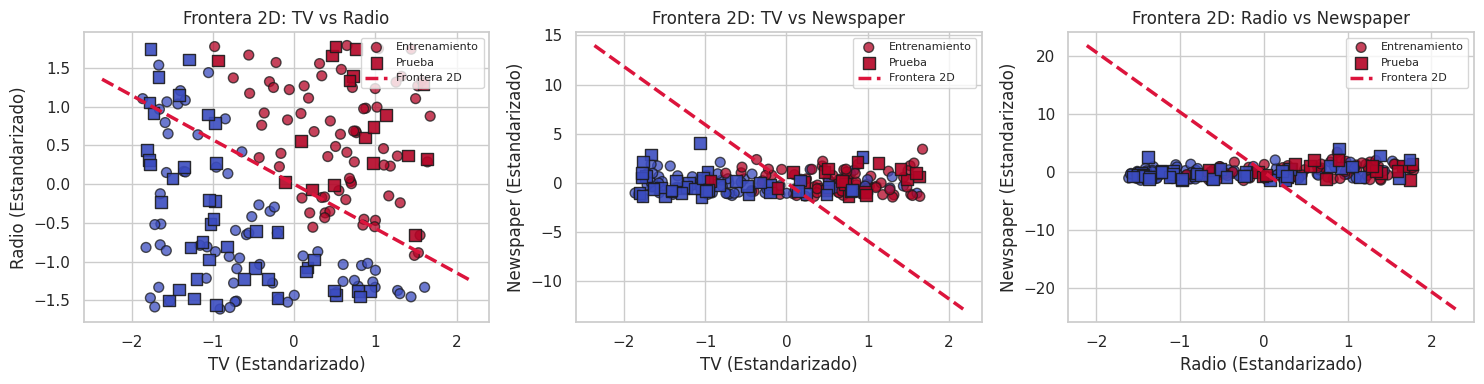

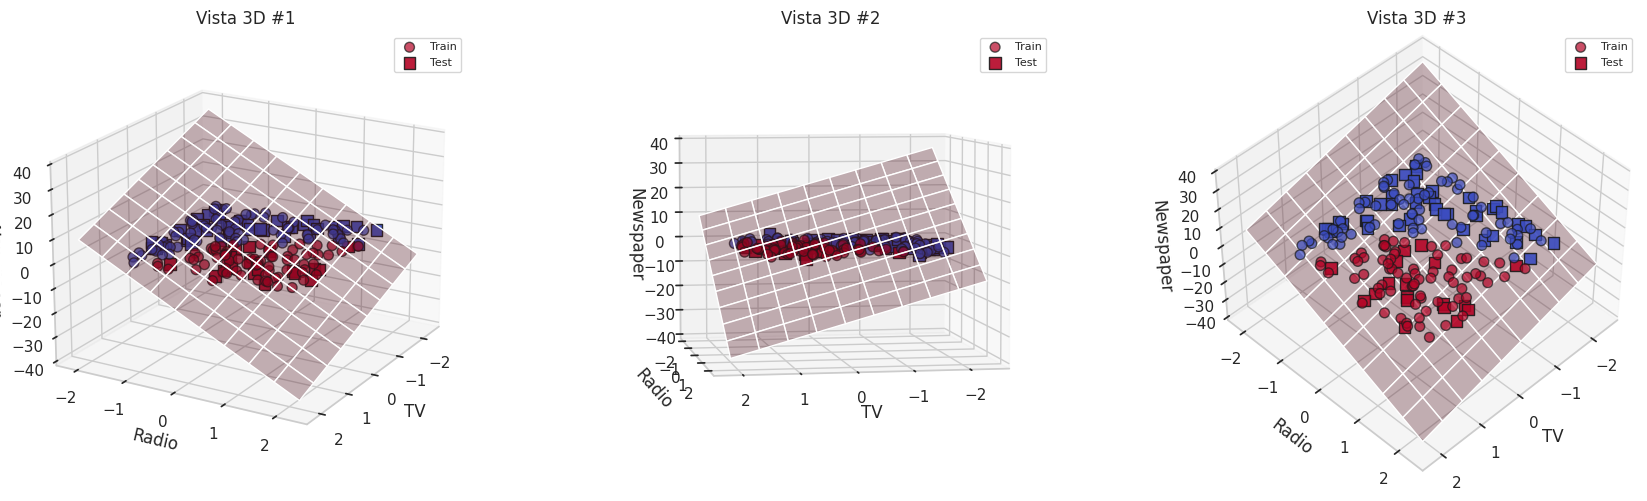

In [23]:
import itertools
from mpl_toolkits.mplot3d import Axes3D

num_variables = len(columnas_x)

# 8.1. GRÁFICOS 1D (Fronteras Marginales por Columna)
fig1, axs1 = plt.subplots(1, num_variables, figsize=(5 * num_variables, 4))
if num_variables == 1:
    axs1 = [axs1]

for i in range(num_variables):
    axs1[i].scatter(X_train_scaled[:, i], y_train, c=y_train, cmap='coolwarm',
                    marker='o', edgecolor='k', s=50, alpha=0.75, label='Entrenamiento')
    axs1[i].scatter(X_test_scaled[:, i], y_test, c=y_test, cmap='coolwarm',
                    marker='s', edgecolor='k', s=70, alpha=0.9, label='Prueba')

    if w[i] != 0:
        limite = -b / w[i]
        axs1[i].axvline(x=limite, color='crimson', linestyle='--', linewidth=2.5, label=f'Límite ({limite:.2f})')

    axs1[i].set_title(f'Frontera 1D: {columnas_x[i]}')
    axs1[i].set_xlabel(f"{columnas_x[i]} (Estandarizado)")
    if i == 0:
        axs1[i].set_ylabel("Clase (0 o 1)")
    axs1[i].legend(fontsize=8)

plt.tight_layout()
plt.show()

# 8.2. GRÁFICOS 2D (Combinaciones por Pares de Variables)
if num_variables >= 2:
    pares = list(itertools.combinations(range(num_variables), 2))
    fig2, axs2 = plt.subplots(1, len(pares), figsize=(5 * len(pares), 4))
    if len(pares) == 1:
        axs2 = [axs2]

    for idx, (f1, f2) in enumerate(pares):
        axs2[idx].scatter(X_train_scaled[:, f1], X_train_scaled[:, f2], c=y_train, cmap='coolwarm',
                          marker='o', edgecolor='k', s=50, alpha=0.75, label='Entrenamiento')
        axs2[idx].scatter(X_test_scaled[:, f1], X_test_scaled[:, f2], c=y_test, cmap='coolwarm',
                          marker='s', edgecolor='k', s=70, alpha=0.9, label='Prueba')

        x_vals = np.array([min(X_train_scaled[:, f1].min(), X_test_scaled[:, f1].min()) - 0.5,
                           max(X_train_scaled[:, f1].max(), X_test_scaled[:, f1].max()) + 0.5])
        if w[f2] != 0:
            y_vals = -(w[f1] * x_vals + b) / w[f2]
            axs2[idx].plot(x_vals, y_vals, color='crimson', linestyle='--', linewidth=2.5, label='Frontera 2D')

        axs2[idx].set_title(f'Frontera 2D: {columnas_x[f1]} vs {columnas_x[f2]}')
        axs2[idx].set_xlabel(f"{columnas_x[f1]} (Estandarizado)")
        axs2[idx].set_ylabel(f"{columnas_x[f2]} (Estandarizado)")
        axs2[idx].legend(fontsize=8)

    plt.tight_layout()
    plt.show()

# 8.3. GRÁFICOS 3D (Si el Dataset tiene exactamente 3 Columnas)
if num_variables == 3:
    fig3 = plt.figure(figsize=(18, 5))
    perspectivas = [(20, 30), (5, 80), (45, 45)]

    for idx, (elev, azim) in enumerate(perspectivas):
        ax3 = fig3.add_subplot(1, 3, idx + 1, projection='3d')

        ax3.scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], X_train_scaled[:, 2],
                   c=y_train, cmap='coolwarm', marker='o', edgecolor='k', s=50, alpha=0.7, label='Train')
        ax3.scatter(X_test_scaled[:, 0], X_test_scaled[:, 1], X_test_scaled[:, 2],
                   c=y_test, cmap='coolwarm', marker='s', edgecolor='k', s=70, alpha=0.9, label='Test')

        if w[2] != 0:
            x_min = min(X_train_scaled[:, 0].min(), X_test_scaled[:, 0].min()) - 0.5
            x_max = max(X_train_scaled[:, 0].max(), X_test_scaled[:, 0].max()) + 0.5
            y_min = min(X_train_scaled[:, 1].min(), X_test_scaled[:, 1].min()) - 0.5
            y_max = max(X_train_scaled[:, 1].max(), X_test_scaled[:, 1].max()) + 0.5

            xx, yy = np.meshgrid(np.linspace(x_min, x_max, 10), np.linspace(y_min, y_max, 10))
            zz = -(w[0] * xx + w[1] * yy + b) / w[2]

            ax3.plot_surface(xx, yy, zz, alpha=0.3, color='crimson')

        ax3.set_title(f"Vista 3D #{idx+1}")
        ax3.set_xlabel(f"{columnas_x[0]}")
        ax3.set_ylabel(f"{columnas_x[1]}")
        ax3.set_zlabel(f"{columnas_x[2]}")
        ax3.view_init(elev=elev, azim=azim)
        ax3.legend(fontsize=8)

    plt.tight_layout()
    plt.show()